# 09 Hyper-heuristic for the sampling route (task 6 extension)
A **hyper-heuristic** searches the space of heuristics rather than the space of solutions: instead of committing to one move, a high-level strategy decides, at every step, which low-level heuristic to apply, and an acceptance criterion decides whether to keep the result. A *selection* hyper-heuristic does this over a fixed set of existing low-level heuristics, learning online which ones are paying off, so the same strategy can adapt to different instances without retuning.

**Design.**
- *Problem:* the task 6 tour on the metric closure $D$ from the office (same reduction, same expansion to a walk).
- *Low-level heuristics (LLHs):* four random perturbative moves on the tour, office fixed: **2-opt** (reverse a segment), **swap** (exchange two locations), **relocate** (move one location), **or-opt** (move a block of 2 or 3, possibly reversed).
- *Selection:* **random** (uniform each step) or **adaptive** probability matching: each LLH keeps a weight, an exponential average (rate 0.05) of whether its last applications improved the current tour; it is chosen with probability proportional to its weight, with a floor of 5% so no LLH is abandoned.
- *Acceptance:* **late acceptance hill climbing** (history 50): a candidate is accepted if it is no worse than the current tour or than the current tour 50 iterations ago, which lets the search leave local optima without a temperature schedule.
- *Budget:* 30,000 LLH applications per run, starting from the nearest-neighbour tour, 10 seeds per configuration.

**Baselines.** NN + 2-opt local search (task 6, deterministic); each LLH alone under the same acceptance and budget (single-heuristic search); and the branch-and-bound optimum where it can be computed (NYT and office-nearest subsets, as in task 6).

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
import time
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import water
from water import hh, paths, plot, tasks, tsp

plot.setup()
nets = water.load_all()
ITERS, SEEDS = 30000, range(10)
CONFIGS = {**{f'only {h}': ({h: hh.LLH[h]}, 'random') for h in hh.LLH},
           'HH random': (hh.LLH, 'random'), 'HH adaptive': (hh.LLH, 'adaptive')}
COLORS = dict(zip(CONFIGS, [plot.PALETTE[0], plot.PALETTE[1], plot.PALETTE[2], plot.PALETTE[3], plot.PALETTE[8], plot.PALETTE[5]]))

In [2]:
print(inspect.getsource(hh.search))

def search(D, start, heuristics, iters=20000, select='adaptive', history=50, rate=0.05, p_min=0.05, seed=0):
    """late acceptance hill climbing driven by a selection rule over the given heuristics.

    select='random': uniform choice each iteration (with one heuristic this is a plain
    single-heuristic search). select='adaptive': probability matching, each heuristic's
    weight tracks how often it recently improved the current tour; every heuristic keeps
    at least p_min probability so none is abandoned for good.
    acceptance: take the candidate if it is no worse than the current tour or than the
    current tour of `history` iterations ago.
    returns best tour, its cost, the best-cost trace and the selection counts."""
    rng = random.Random(seed)
    names = list(heuristics)
    cur, cur_c = list(start), cost(D, start)
    best, best_c = list(cur), cur_c
    hist = [cur_c] * history
    w = dict.fromkeys(names, 1.0)
    used = dict.fromkeys(names, 0)
    trace = np.empty

## Problems
Each instance's closure is reordered so the office is index 0. Problems with a proven optimum: full NYT and office-nearest subsets with $k\in\{12,16,20\}$ (20 only where branch and bound finishes within 60 s). Full HAN, FOS and PES have no proven optimum and are compared with the task 6 route and the root lower bound.

In [3]:
problems = []
for name, net in nets.items():
    D, nxt, ids, index = tasks.metric_closure(net)
    o = index[net.office]
    order = [o] + sorted(np.argsort(D[o], kind='stable')[1:], key=lambda i: D[o, i])
    for k in sorted({12, 16, 20, len(ids)}):
        if k > len(ids):
            continue
        sub = order[:k]
        Dk = D[np.ix_(sub, sub)]
        nn = tsp.nearest_neighbor(Dk, 0)
        t2, _ = tsp.two_opt(Dk, nn)
        _, opt, proven, root, _ = tsp.branch_and_bound(Dk, 0, t2, time_limit=60)
        if not proven and k != len(ids):
            continue
        problems.append({'inst': name, 'k': k, 'full': k == len(ids), 'D': Dk, 'sub': sub, 'nxt': nxt, 'ids': ids,
                         'nn': nn, 't2': tsp.tour_length(Dk, t2), 'opt': opt if proven else None, 'root': root, 'best_known': opt})
for p in problems:
    print(f'{p["inst"]} k={p["k"]}{" (full)" if p["full"] else ""}: 2-opt {p["t2"]:,.1f}, '
          f'{"optimum " + format(p["opt"], ",.1f") if p["opt"] else "no proven optimum, root bound " + format(p["root"], ",.1f")}')

NYT k=12: 2-opt 4,725.6, optimum 4,725.6
NYT k=16: 2-opt 5,728.7, optimum 5,728.7
NYT k=20 (full): 2-opt 7,622.3, optimum 7,072.1
HAN k=12: 2-opt 19,626.9, optimum 19,626.9
HAN k=16: 2-opt 26,737.6, optimum 25,431.2
HAN k=20: 2-opt 26,249.2, optimum 26,249.2
HAN k=32 (full): 2-opt 40,810.0, no proven optimum, root bound 30,605.2
FOS k=12: 2-opt 12,353.3, optimum 12,353.3
FOS k=16: 2-opt 14,042.9, optimum 14,042.9
FOS k=20: 2-opt 20,548.8, optimum 19,357.7
FOS k=37 (full): 2-opt 30,424.3, no proven optimum, root bound 25,147.3
PES k=12: 2-opt 3,671.6, optimum 3,671.6
PES k=16: 2-opt 4,892.7, optimum 4,892.7
PES k=71 (full): 2-opt 35,510.1, no proven optimum, root bound 22,195.1


## Runs and verification
Every returned tour must be a permutation of the problem's locations with the office first, its reported cost must equal `tsp.tour_length`, and it can never be shorter than a proven optimum (which also cross-checks branch and bound). The best tour of each full instance is expanded to a walk and validated as in task 6.

In [4]:
runs = []
for p in problems:
    for cfg, (H, sel) in CONFIGS.items():
        for s in SEEDS:
            t0 = time.perf_counter()
            tour, c, trace, used = hh.search(p['D'], p['nn'], H, iters=ITERS, select=sel, seed=s)
            sec = time.perf_counter() - t0
            assert tour[0] == 0 and sorted(tour) == list(range(len(p['D'])))
            assert abs(c - tsp.tour_length(p['D'], tour)) < 1e-6
            assert p['opt'] is None or c >= p['opt'] - 1e-6
            runs.append({'inst': p['inst'], 'k': p['k'], 'full': p['full'], 'cfg': cfg, 'seed': s, 'cost': c,
                         'tour': tour, 'seconds': sec, 'used': used,
                         'trace': trace if p['full'] and p['inst'] == 'PES' else None})
print(f'{len(runs)} runs, all valid')

for p in [p for p in problems if p['full']]:
    best = min((r for r in runs if r['inst'] == p['inst'] and r['full']), key=lambda r: r['cost'])
    walk = [p['ids'][p['sub'][0]]]
    for a, b in zip(best['tour'], best['tour'][1:] + best['tour'][:1]):
        walk += [p['ids'][i] for i in paths.fw_path(p['nxt'], p['sub'][a], p['sub'][b])[1:]]
    net = nets[p['inst']]
    pipes = {frozenset(e[:2]) for e in net.pipes}
    assert walk[0] == walk[-1] == net.office and set(walk) == set(net.coords)
    assert all(frozenset(e) in pipes for e in zip(walk, walk[1:]))
    assert abs(sum(net.length(a, b) for a, b in zip(walk, walk[1:])) - best['cost']) < 1e-6
    p['hh_best'] = best
print('best full-instance tours expand to valid walks')

840 runs, all valid
best full-instance tours expand to valid walks


## Results on problems with a proven optimum

In [5]:
known = [p for p in problems if p['opt']]
rows = []
summary = {}
for cfg in ['NN', 'NN + 2-opt', *CONFIGS]:
    if cfg == 'NN':
        g = [tsp.tour_length(p['D'], p['nn']) / p['opt'] - 1 for p in known]
    elif cfg == 'NN + 2-opt':
        g = [p['t2'] / p['opt'] - 1 for p in known]
    else:
        g = [r['cost'] / p['opt'] - 1 for p in known for r in runs if r['cfg'] == cfg and r['inst'] == p['inst'] and r['k'] == p['k']]
    g = np.array(g)
    summary[cfg] = g
    sec = np.median([r['seconds'] for r in runs if r['cfg'] == cfg]) if cfg in CONFIGS else None
    rows.append([cfg, 100 * g.mean(), 100 * g.max(), 100 * np.mean(g < 1e-9), f'{sec:.2f}' if sec else '-'])
    print(f'{cfg:12s} mean gap {100*g.mean():5.2f}% | worst {100*g.max():5.2f}% | optimal in {100*np.mean(g < 1e-9):5.1f}% '
          f'of {len(g)} {"runs" if cfg in CONFIGS else "problems"}' + (f' | median {sec:.2f} s per run' if sec else ''))

NN           mean gap 21.25% | worst 35.54% | optimal in   0.0% of 11 problems
NN + 2-opt   mean gap  1.73% | worst  7.78% | optimal in  72.7% of 11 problems
only 2-opt   mean gap  0.29% | worst  7.96% | optimal in  94.5% of 110 runs | median 0.17 s per run
only swap    mean gap 14.29% | worst 30.33% | optimal in  14.5% of 110 runs | median 0.16 s per run
only relocate mean gap 11.11% | worst 25.79% | optimal in  28.2% of 110 runs | median 0.16 s per run
only or-opt  mean gap  2.90% | worst 11.40% | optimal in  60.9% of 110 runs | median 0.16 s per run
HH random    mean gap  0.23% | worst  4.66% | optimal in  94.5% of 110 runs | median 0.16 s per run
HH adaptive  mean gap  0.19% | worst  4.66% | optimal in  93.6% of 110 runs | median 0.19 s per run


In [6]:
print('adaptive selection shares (all runs):')
share = Counter()
for r in runs:
    if r['cfg'] == 'HH adaptive':
        share.update(r['used'])
tot = sum(share.values())
print({h: f'{100 * v / tot:.1f}%' for h, v in share.items()})

adaptive selection shares (all runs):
{'2-opt': '25.3%', 'swap': '24.8%', 'relocate': '25.2%', 'or-opt': '24.7%'}


## Full instances

In [7]:
full_rows = []
for p in [p for p in problems if p['full']]:
    line = {}
    for cfg in CONFIGS:
        cs = [r['cost'] for r in runs if r['cfg'] == cfg and r['inst'] == p['inst'] and r['full']]
        line[cfg] = (min(cs), float(np.median(cs)))
    ref = p['opt'] or p['t2']
    print(f'{p["inst"]}: 2-opt {p["t2"]:,.1f}' + (f', optimum {p["opt"]:,.1f}' if p['opt'] else f', root bound {p["root"]:,.1f}') + ' | '
          + ' | '.join(f'{c}: best {b:,.0f} median {m:,.0f}' for c, (b, m) in line.items()))
    full_rows.append([p['inst'], p['t2'], line['only 2-opt'][0], line['HH random'][0], line['HH random'][1],
                      line['HH adaptive'][0], line['HH adaptive'][1], 'optimal' if p['opt'] else f'{p["root"]:,.0f}'])

plot.table('hh_full', full_rows,
           ['Inst.', 'NN + 2-opt', 'Only 2-opt best', 'HH rand. best', 'HH rand. median', 'HH adapt. best', 'HH adapt. median', 'Optimum / bound'],
           ['{}', '{:,.0f}', '{:,.0f}', '{:,.0f}', '{:,.0f}', '{:,.0f}', '{:,.0f}', '{}'])
plot.table('hh_known', rows, ['Method', 'Mean gap (\\%)', 'Worst gap (\\%)', 'Optimal (\\%)', 'Time per run (s)'],
           ['{}', '{:.2f}', '{:.2f}', '{:.0f}', '{}'])

NYT: 2-opt 7,622.3, optimum 7,072.1 | only 2-opt: best 7,072 median 7,072 | only swap: best 8,095 median 8,842 | only relocate: best 7,072 median 8,095 | only or-opt: best 7,072 median 7,072 | HH random: best 7,072 median 7,072 | HH adaptive: best 7,072 median 7,072
HAN: 2-opt 40,810.0, root bound 30,605.2 | only 2-opt: best 40,810 median 41,696 | only swap: best 43,802 median 43,802 | only relocate: best 43,802 median 43,802 | only or-opt: best 43,016 median 43,016 | HH random: best 40,810 median 40,810 | HH adaptive: best 40,810 median 40,810
FOS: 2-opt 30,424.3, root bound 25,147.3 | only 2-opt: best 30,424 median 32,097 | only swap: best 32,164 median 32,241 | only relocate: best 30,424 median 31,679 | only or-opt: best 30,424 median 32,085 | HH random: best 30,424 median 30,424 | HH adaptive: best 30,424 median 32,046
PES: 2-opt 35,510.1, root bound 22,195.1 | only 2-opt: best 34,766 median 35,064 | only swap: best 37,748 median 37,771 | only relocate: best 35,200 median 36,029 | 

## Figure

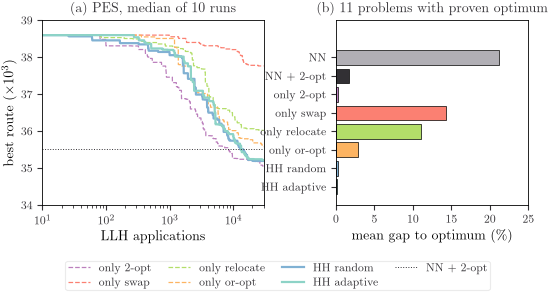

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.27, 2.4), gridspec_kw={'width_ratios': [1.15, 1], 'wspace': 0.35})
pes = next(p for p in problems if p['full'] and p['inst'] == 'PES')
x = np.arange(1, ITERS + 1)
for j, cfg in enumerate(CONFIGS):
    tr = np.median([r['trace'] for r in runs if r['cfg'] == cfg and r['trace'] is not None], axis=0)
    a1.plot(x, tr / 1e3, color=COLORS[cfg], lw=1.6 if cfg.startswith('HH') else 0.9,
            ls='-' if cfg.startswith('HH') else '--', label=cfg)
a1.axhline(pes['t2'] / 1e3, color=plot.INK, lw=0.7, ls=':', label='NN + 2-opt')
a1.set(xscale='log', xlabel='LLH applications', ylabel=r'best route ($\times 10^3$)', title='(a) PES, median of 10 runs')
a1.set_xlim(10, ITERS); a1.set_ylim(34, 39)
names = ['NN', 'NN + 2-opt', *CONFIGS]
cols = [plot.GRID, plot.INK] + [COLORS[c] for c in CONFIGS]
a2.barh(range(len(names)), [100 * summary[n].mean() for n in names], color=cols, edgecolor='k', linewidth=0.5)
a2.set_yticks(range(len(names)), names)
a2.invert_yaxis()
a2.set(xlabel=r'mean gap to optimum (\%)', title=f'(b) {len(known)} problems with proven optimum')
fig.legend(*a1.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4)
plot.save(fig, 'hyperheuristic')
plt.show()

## Interpretation
- **Against the optimum.** On the 11 problems with a proven optimum both hyper-heuristics are within about 0.2% on average and optimal in about 94% of runs, slightly better on average than the best single heuristic (2-opt alone, 0.29%) and with a smaller worst case (4.66% against 7.96%). Swap and relocate alone are poor (11 to 14% gaps): they cannot untangle crossing legs, which 2-opt removes directly.
- **Robustness.** The clearest gain is in the spread over seeds on the full instances: the random-selection hyper-heuristic reaches the best known HAN and FOS routes in every run (median 40,810 and 30,424), whereas 2-opt alone has medians of 41,696 and 32,097. On PES the hyper-heuristic finds the best route of the whole study, 34,700, 2.3% shorter than the task 6 route (35,510); its median (35,200) is slightly worse than 2-opt alone (35,064), so on PES mixing in weaker moves costs some consistency.
- **Adaptive selection.** The adaptive rule ends up choosing the four heuristics almost uniformly (about 25% each) and is no better than random selection. Once the search is near a local optimum, improvements are rare for every heuristic, so the credit each one earns decays to the same floor and the rule cannot tell them apart. A reward based on accepted moves, or on improvement size, would be the natural next step.
- **Status.** Like the task 6 heuristics, these routes carry no optimality guarantee: for HAN, FOS and PES the gap to the root bound remains large. Each run costs about 0.16 s for 30,000 applications, far more than NN + 2-opt but polynomial.

## Complexity
Each iteration applies one LLH, $O(n)$ for the list operations, evaluates the tour in $O(n)$, and updates the selection weights in $O(h)$ for $h=4$ heuristics; a run costs $O(I\,n)$ for $I$ iterations, independent of the instance's structure, and $O(n+L)$ memory for the tour and the acceptance history $L$. It is therefore polynomial with a user-chosen budget, between the cheap NN + 2-opt and the exponential branch and bound, and it carries no optimality guarantee.